# 02 · BA → county mapping: validation

Built by `python -m glg.build.ba_weather_map` (method in DATA.md, "BA → county mapping").
Each county gets a weight per BA: the BA's share of the county's residential customers
(EIA-861 territories + sales, raked to county population). Weather features weight counties
by weight × population.

Validation BAs: **ERCO, DUK, SRP (with AZPS), FPL, DOM**. Maps show the weight (0–1) for
2024; FPL is shown before and after Gulf Power joined (2019 vs 2023).

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import polars as pl
from glg.build import ba_weather_map as bwm

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
INK, MUTED = "#1f2937", "#6b7280"

m = pl.read_csv(bwm.MAP_PATH, schema_overrides={"county_fips": pl.Utf8})
pop = pl.read_csv(bwm.POP_PATH, schema_overrides={"county_fips": pl.Utf8})
summary = pl.read_csv(bwm.SUMMARY_PATH)
shapes = bwm.county_shapes()
states = shapes.dissolve(by="state").reset_index()

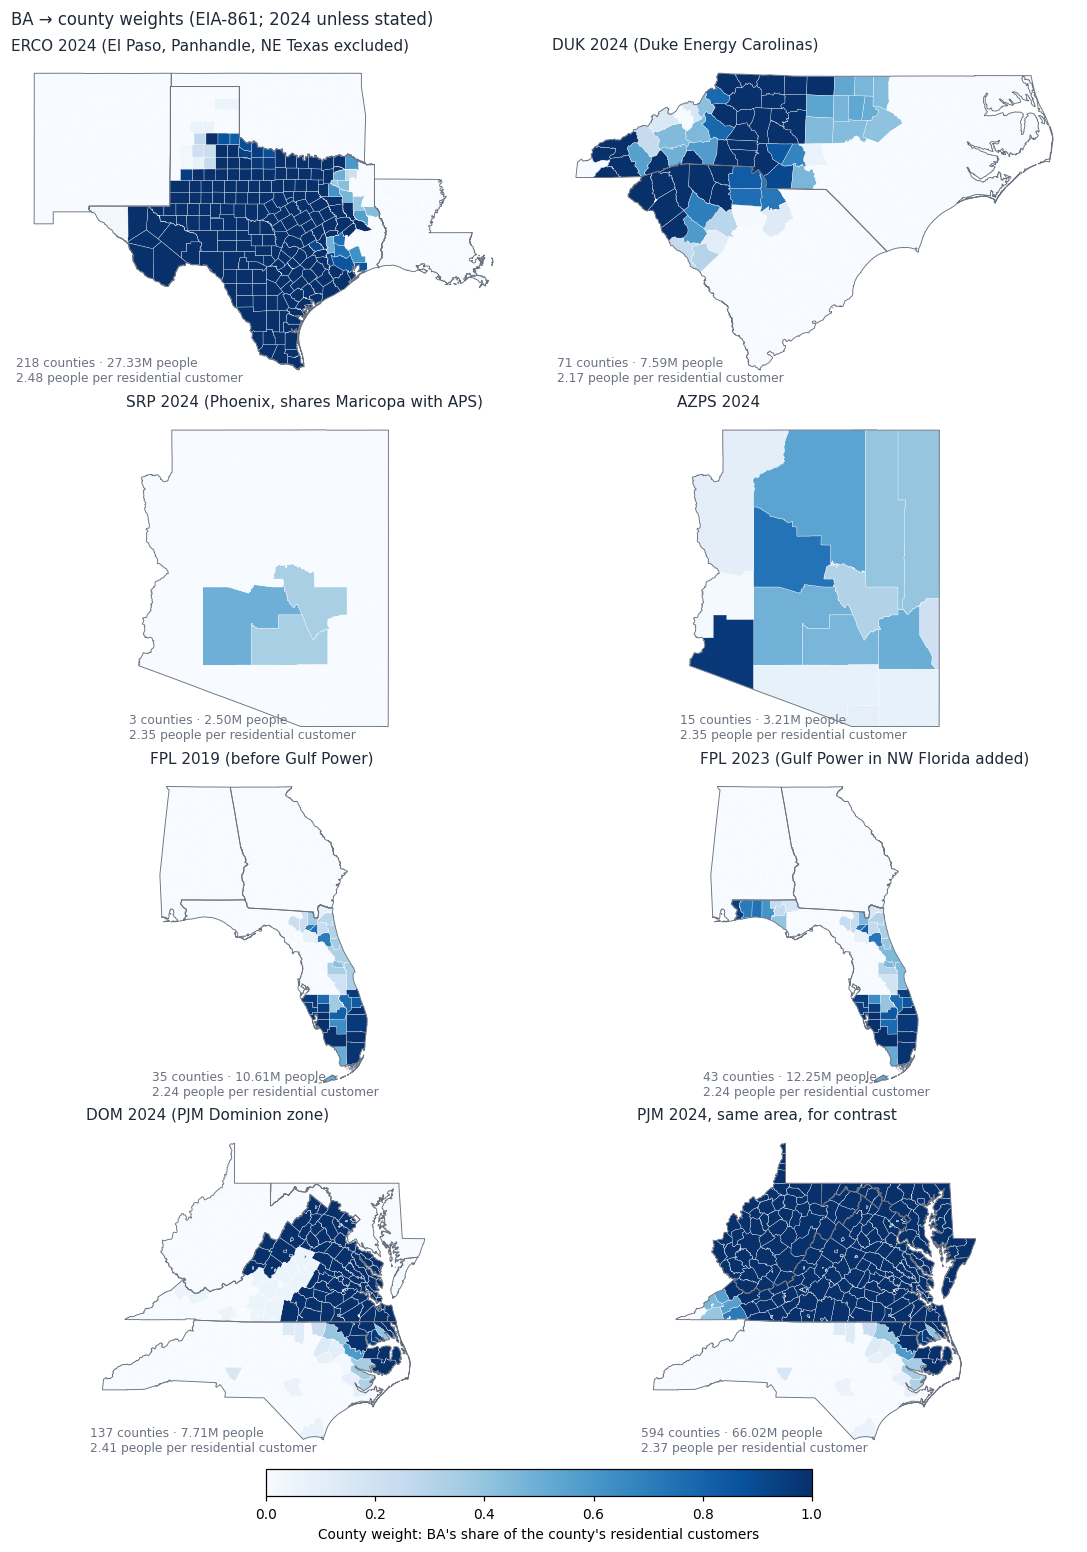

In [2]:
def ba_map(ax, ba, year, extent_states, title=None):
    w = m.filter(pl.col("ba") == ba, pl.col("year") == year).select("county_fips", "weight").to_pandas()
    g = shapes[shapes.state.isin(extent_states)].merge(w, on="county_fips", how="left")
    g["weight"] = g["weight"].fillna(0)
    g.plot(ax=ax, column="weight", cmap="Blues", vmin=0, vmax=1, edgecolor="white", linewidth=0.2)
    states[states.state.isin(extent_states)].boundary.plot(ax=ax, color=MUTED, linewidth=0.6)
    p = summary.filter(pl.col("ba") == ba, pl.col("year") == year).row(0, named=True)
    ax.set_title(title or f"{ba} {year}", loc="left", color=INK, fontsize=10)
    ax.text(0.01, 0.01, f"{p['n_counties']} counties · {p['population']/1e6:.2f}M people\n"
            f"{p['people_per_customer']:.2f} people per residential customer",
            transform=ax.transAxes, fontsize=8, color=MUTED)
    ax.set_axis_off()

panels = [
    ("ERCO", 2024, ["TX", "OK", "NM", "LA"], "ERCO 2024 (El Paso, Panhandle, NE Texas excluded)"),
    ("DUK", 2024, ["NC", "SC"], "DUK 2024 (Duke Energy Carolinas)"),
    ("SRP", 2024, ["AZ"], "SRP 2024 (Phoenix, shares Maricopa with APS)"),
    ("AZPS", 2024, ["AZ"], "AZPS 2024"),
    ("FPL", 2019, ["FL", "AL", "GA"], "FPL 2019 (before Gulf Power)"),
    ("FPL", 2023, ["FL", "AL", "GA"], "FPL 2023 (Gulf Power in NW Florida added)"),
    ("DOM", 2024, ["VA", "NC", "WV", "MD", "DC"], "DOM 2024 (PJM Dominion zone)"),
    ("PJM", 2024, ["VA", "NC", "WV", "MD", "DC"], "PJM 2024, same area, for contrast"),
]
fig, axes = plt.subplots(4, 2, figsize=(10, 14), layout="constrained")
for ax, (ba, y, ext, t) in zip(axes.flat, panels):
    ba_map(ax, ba, y, ext, t)
sm = plt.cm.ScalarMappable(cmap="Blues", norm=plt.Normalize(0, 1))
fig.colorbar(sm, ax=axes, orientation="horizontal", fraction=0.02, pad=0.01, shrink=0.5,
             label="County weight: BA's share of the county's residential customers")
fig.suptitle("BA → county weights (EIA-861; 2024 unless stated)", x=0.02, ha="left", color=INK)
fig.savefig("../report/figures/ba_mapping_validation.png", dpi=110, bbox_inches="tight")

### What the maps show

- **ERCO** covers Texas except El Paso (EPE), the Panhandle/South Plains (SWPP) and the
  east-Texas Entergy area (MISO). Harris County (Houston) comes out ~86% ERCO: Entergy Texas
  lists it for a sliver and a county list can't size a sliver (the true figure is ~99%).
- **DUK** is the western/central Carolinas (Charlotte, Greensboro, Upstate SC). Wake (Raleigh)
  shows ~41% DUK for the same sliver reason; it is really almost all CPLE.
- **SRP / AZPS** split Maricopa County about half and half, as they should; APS also covers
  rural Arizona (Yavapai, Yuma, Navajo, ...).
- **FPL** gains the Panhandle (Escambia, Okaloosa, Bay, ...) in 2022 when Gulf Power moved
  from SOCO. EIA-930 FPL demand shows the matching step from about **mid-2022** (not January),
  so 2022 is a transition year for FPL and SOCO.
- **DOM** is Northern Virginia, Richmond, Hampton Roads and north-east North Carolina;
  south-west Virginia (AEP) and the Eastern Shore (DPL) are excluded.

In [3]:
# Every BA in the shortlist: population and people per residential customer by year
shortlist = pl.read_csv(bwm.REFERENCE_DIR / "ba_shortlist.csv").filter(pl.col("include") != "no")
s = summary.filter(pl.col("ba").is_in(shortlist["series"].implode()))
with pl.Config(tbl_rows=40, tbl_cols=20, tbl_width_chars=160):
    display(s.pivot(on="year", index="ba", values="population")
             .with_columns((pl.all().exclude("ba") / 1e6).round(2)))
    display(s.pivot(on="year", index="ba", values="people_per_customer"))

ba,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""AZPS""",2.7,2.76,2.81,2.88,2.95,3.01,3.06,3.11,3.15,3.21,3.25
"""BPAT""",3.64,3.71,3.75,3.79,3.87,3.88,3.93,3.95,3.98,4.02,4.05
"""CISO""",31.87,32.1,32.3,32.38,32.43,32.48,32.14,32.08,32.19,32.36,32.33
"""CPLE""",4.37,4.46,4.49,4.54,4.57,4.61,4.65,4.75,4.83,4.92,4.98
"""DOM""",7.28,7.33,7.39,7.44,7.49,7.51,7.54,7.57,7.62,7.71,7.73
"""DOPD""",0.07,0.07,0.07,0.07,0.07,0.08,0.08,0.08,0.08,0.08,0.08
"""DUK""",6.82,6.87,6.95,7.02,7.1,7.17,7.27,7.34,7.47,7.59,7.7
"""ERCO""",23.54,23.95,24.32,24.69,24.97,25.21,25.7,26.21,26.73,27.33,27.69
"""FPC""",3.59,3.63,3.71,3.76,3.8,3.85,3.9,4.03,4.11,4.17,4.11


ba,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""AZPS""",2.48,2.47,2.46,2.44,2.43,2.43,2.41,2.39,2.37,2.35,2.33
"""BPAT""",2.39,2.4,2.39,2.39,2.4,2.38,2.36,2.34,2.32,2.31,2.3
"""CISO""",2.89,2.88,2.85,2.84,2.81,2.79,2.75,2.72,2.69,2.67,2.65
"""CPLE""",2.29,2.28,2.26,2.25,2.24,2.22,2.21,2.2,2.19,2.18,2.17
"""DOM""",2.52,2.51,2.5,2.49,2.48,2.46,2.43,2.42,2.41,2.41,2.38
"""DOPD""",2.26,2.26,2.26,2.26,2.25,2.43,2.42,2.4,2.38,2.38,2.37
"""DUK""",2.28,2.26,2.25,2.24,2.23,2.21,2.2,2.19,2.18,2.17,2.16
"""ERCO""",2.64,2.63,2.6,2.55,2.53,2.53,2.49,2.49,2.49,2.48,2.47
"""FPC""",2.26,2.26,2.26,2.25,2.24,2.23,2.21,2.23,2.25,2.23,2.17


In [4]:
# Year-on-year change in mapped population > 3%: boundary changes or reporting changes
chg = (summary.sort("ba", "year")
       .with_columns((pl.col("population") / pl.col("population").shift(1).over("ba") - 1).alias("chg"))
       .filter(pl.col("chg").abs() > 0.03, pl.col("ba").is_in(shortlist["series"].implode())))
chg.select("ba", "year", "population", (pl.col("chg") * 100).round(1).alias("chg_pct"))

ba,year,population,chg_pct
str,i64,i64,f64
"""DOPD""",2020,80392,9.6
"""FPC""",2022,4026799,3.2
"""FPL""",2022,11986436,10.4
"""SOCO""",2021,15948598,6.4
"""SOCO""",2022,15237406,-4.5
